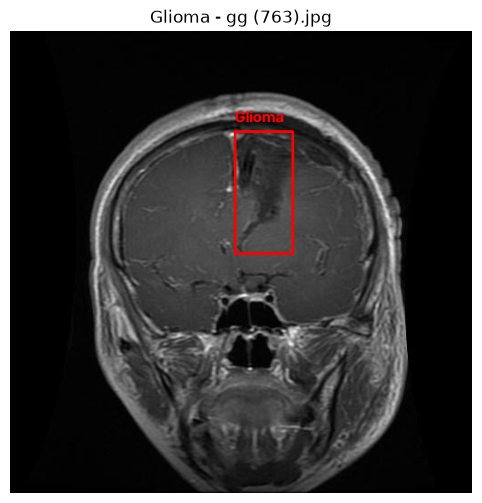

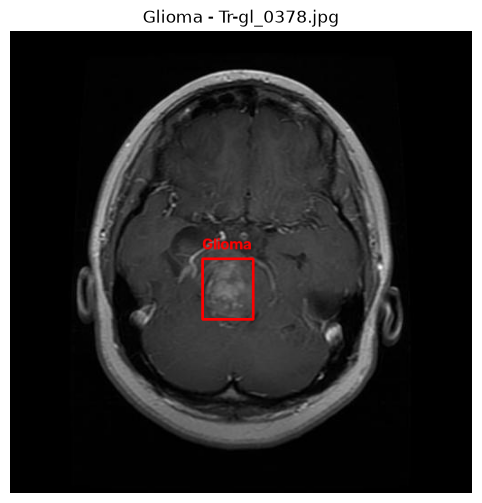

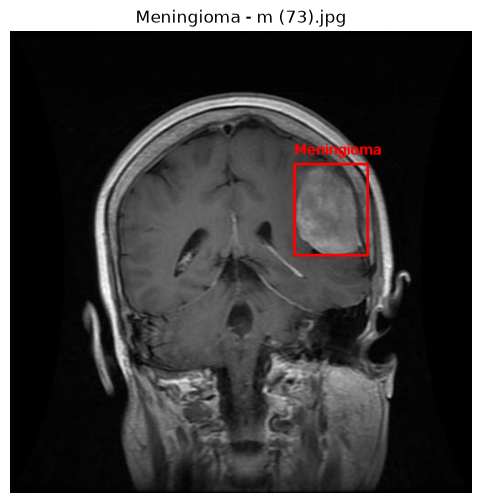

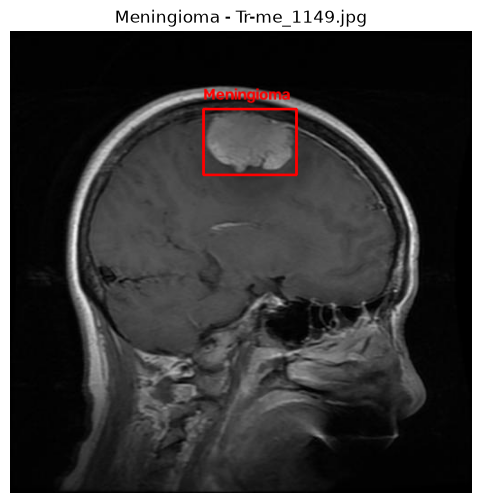

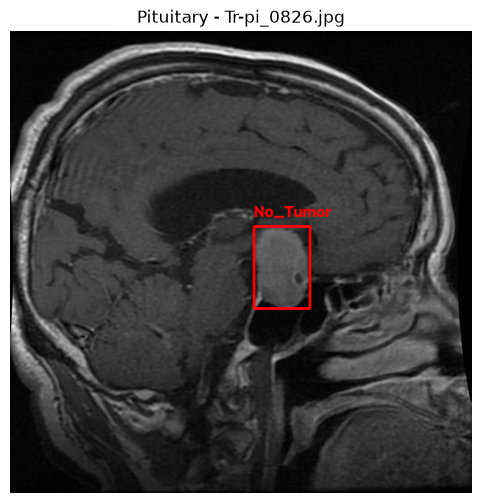

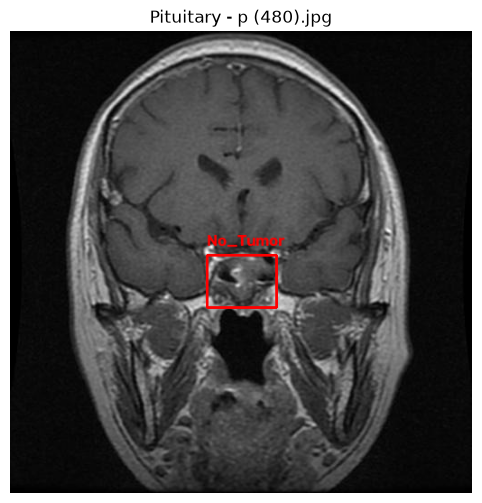

In [1]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Chemin principal du dataset
dataset_dir = Path("../../data/1_split/Train")

# Noms des classes
classes = ["Glioma", "Meningioma", "Pituitary", "No_Tumor"]

# Parcourir chaque catégorie
for categorie in classes:

    images_dir = dataset_dir / categorie / "images"
    labels_dir = dataset_dir / categorie / "labels"

    # Récupérer les images
    images = []

    for ext in ["*.jpg", "*.jpeg", "*.png", "*.bmp"]:
        images.extend(images_dir.glob(ext))

    # Afficher seulement 2 images par catégorie
    for image_path in images[:2]:

        # Charger l'image
        image = cv2.imread(str(image_path))

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Chercher l'annotation correspondante
        label_path = labels_dir / (image_path.stem + ".txt")

        if not label_path.exists():
            print("Annotation manquante :", image_path.name)
            continue

        # Lire les annotations
        with open(label_path, "r") as file:
            for line in file:

                values = line.split()

                if len(values) != 5:
                    continue

                class_id = int(values[0])
                x, y, w, h = map(float, values[1:])

                # Convertir les coordonnées en pixels
                height, width = image.shape[:2]

                x1 = int((x - w / 2) * width)
                y1 = int((y - h / 2) * height)
                x2 = int((x + w / 2) * width)
                y2 = int((y + h / 2) * height)

                # Dessiner le rectangle
                cv2.rectangle(
                    image, (x1, y1), (x2, y2),
                    (255, 0, 0), 2
                )

                # Récupérer le nom de la classe annotée
                if 0 <= class_id < len(classes):
                    nom_classe = classes[class_id]
                else:
                    nom_classe = str(class_id)

                cv2.putText(
                    image, nom_classe,
                    (x1, max(y1 - 10, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (255, 0, 0), 2
                )

        # Afficher l'image annotée
        plt.figure(figsize=(6, 6))
        plt.imshow(image)
        plt.title(categorie + " - " + image_path.name)
        plt.axis("off")
        plt.show()


In [2]:

from pathlib import Path

# Chemin du dossier Train
train_dir = Path("../../data/1_split/Train")

# Compteurs
avec_annotation = 0
sans_annotation = 0

# Parcourir chaque catégorie
for categorie in train_dir.iterdir():

    if categorie.is_dir():

        # Dossiers des images et des annotations
        images_dir = categorie / "images"
        labels_dir = categorie / "labels"

        # Parcourir les images JPG
        for image in images_dir.iterdir():
            if image.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:

             # Nom sans extension
                nom = image.stem

                # Chercher le fichier TXT correspondant
                annotation = labels_dir / (nom + ".txt")

                if annotation.exists():
                    avec_annotation += 1
                else:
                    print("Annotation manquante :", image.name)
                    sans_annotation += 1

# Afficher le bilan
print("Images avec annotation :", avec_annotation)
print("Images sans annotation :", sans_annotation)


Annotation manquante : aug_369.jpg
Annotation manquante : aug_131.jpg
Annotation manquante : aug_308.jpg
Annotation manquante : aug_338.jpg
Annotation manquante : aug_449.jpg
Annotation manquante : aug_354.jpg
Annotation manquante : aug_324.jpg
Annotation manquante : aug_56.jpg
Annotation manquante : aug_179.jpg
Annotation manquante : aug_41.jpg
Annotation manquante : aug_261.jpg
Annotation manquante : aug_213.jpg
Annotation manquante : aug_198.jpg
Annotation manquante : aug_108.jpg
Annotation manquante : aug_28.jpg
Annotation manquante : aug_304.jpg
Annotation manquante : aug_48.jpg
Annotation manquante : aug_72.jpg
Annotation manquante : aug_394.jpg
Annotation manquante : aug_307.jpg
Annotation manquante : aug_511.jpg
Annotation manquante : aug_191.jpg
Annotation manquante : aug_130.jpg
Annotation manquante : aug_82.jpg
Annotation manquante : aug_216.jpg
Annotation manquante : aug_288.jpg
Annotation manquante : aug_16.jpg
Annotation manquante : aug_202.jpg
Annotation manquante : aug_

In [3]:

from pathlib import Path

train_dir = Path("../../data/1_split/Train")

annotations_sans_image = 0

for categorie in train_dir.iterdir():

    if categorie.is_dir():

        images_dir = categorie / "images"
        labels_dir = categorie / "labels"

        # Récupérer les noms des images sans extension
        noms_images = []

        for image in images_dir.iterdir():
            if image.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
                noms_images.append(image.stem)

        # Vérifier chaque annotation
        for label in labels_dir.glob("*.txt"):

            if label.stem not in noms_images:
                print("Annotation sans image :", label.name)
                annotations_sans_image += 1

print("Total des annotations sans image :", annotations_sans_image)



Total des annotations sans image : 0


In [4]:
from pathlib import Path

train_dir = Path("../../data/1_split/Train")

for categorie in train_dir.iterdir():
    labels_dir = categorie / "labels"

    fichiers = list(labels_dir.glob("*.txt"))

    if fichiers:
        print("Fichier :", fichiers[0])
        print(fichiers[0].read_text())
        break

Fichier : ../../data/1_split/Train/Meningioma/labels/m3 (44).txt
1 0.453125 0.541992 0.199219 0.205078



In [5]:

from pathlib import Path

train_dir = Path("../../data/1_split/Train")

for categorie in train_dir.iterdir():

    labels_dir = categorie / "labels"

    for fichier in labels_dir.glob("*.txt"):

        with open(fichier, "r") as f:
            for ligne in f:

                valeurs = ligne.split()

                # Une annotation YOLO doit contenir 5 valeurs
                if len(valeurs) != 5:
                    print("Format incorrect :", fichier.name)
                    continue

                classe, x, y, largeur, hauteur = map(float, valeurs)

                # Vérifier les coordonnées
                if not (
                    0 <= x <= 1
                    and 0 <= y <= 1
                    and 0 < largeur <= 1
                    and 0 < hauteur <= 1
                    and classe >= 0
                    and classe.is_integer()
                ):
                    print("Annotation incorrecte :", fichier.name)

print("Vérification terminée.")


Vérification terminée.


In [10]:

from pathlib import Path
import shutil

# Dossier source
source_dir = Path("../../data/1_split")

# Dossier destination
destination_dir = Path("../../data/dataset_yolo")

# Correspondance entre les anciens noms et les nouveaux noms
ensembles = {
    "Train": "train",
    "Val": "val",
    "Test": "test"
}

# Extensions des images acceptées
extensions = [".jpg", ".jpeg", ".png", ".bmp"]

# Compteurs
images_copiees = 0
annotations_copiees = 0
images_ignorees = 0

# Parcourir les ensembles
for ancien_nom, nouveau_nom in ensembles.items():

    # Parcourir les catégories
    for categorie in ["Glioma", "Meningioma", "Pituitary", "No Tumor"]:

        images_dir = source_dir / ancien_nom / categorie / "images"
        labels_dir = source_dir / ancien_nom / categorie / "labels"

        # Dossiers de destination
        images_dest = destination_dir / "images" / nouveau_nom
        labels_dest = destination_dir / "labels" / nouveau_nom

        images_dest.mkdir(parents=True, exist_ok=True)
        labels_dest.mkdir(parents=True, exist_ok=True)

        # Parcourir les images
        for image_path in images_dir.iterdir():

            if image_path.suffix.lower() not in extensions:
                continue

            # Chercher l'annotation correspondante
            label_path = labels_dir / (image_path.stem + ".txt")

            # Vérifier l'existence de l'annotation
            if not label_path.exists():
                print("Image ignorée :", image_path.name)
                images_ignorees += 1
                continue

            # Copier l'image
            shutil.copy2(
                image_path,
                images_dest / image_path.name
            )

            # Copier son annotation
            shutil.copy2(
                label_path,
                labels_dest / label_path.name
            )

            images_copiees += 1
            annotations_copiees += 1

print("\n===== BILAN =====")
print("Images copiées :", images_copiees)
print("Annotations copiées :", annotations_copiees)
print("Images ignorées :", images_ignorees)


Image ignorée : aug_369.jpg
Image ignorée : aug_131.jpg
Image ignorée : aug_308.jpg
Image ignorée : aug_338.jpg
Image ignorée : aug_449.jpg
Image ignorée : aug_354.jpg
Image ignorée : aug_324.jpg
Image ignorée : aug_56.jpg
Image ignorée : aug_179.jpg
Image ignorée : aug_41.jpg
Image ignorée : aug_261.jpg
Image ignorée : aug_213.jpg
Image ignorée : aug_198.jpg
Image ignorée : aug_108.jpg
Image ignorée : aug_28.jpg
Image ignorée : aug_304.jpg
Image ignorée : aug_48.jpg
Image ignorée : aug_72.jpg
Image ignorée : aug_394.jpg
Image ignorée : aug_307.jpg
Image ignorée : aug_511.jpg
Image ignorée : aug_191.jpg
Image ignorée : aug_130.jpg
Image ignorée : aug_82.jpg
Image ignorée : aug_216.jpg
Image ignorée : aug_288.jpg
Image ignorée : aug_16.jpg
Image ignorée : aug_202.jpg
Image ignorée : aug_528.jpg
Image ignorée : aug_277.jpg
Image ignorée : aug_7.jpg
Image ignorée : aug_281.jpg
Image ignorée : aug_132.jpg
Image ignorée : aug_64.jpg
Image ignorée : aug_149.jpg
Image ignorée : aug_398.jpg
Im

In [12]:

from pathlib import Path
import shutil

# Dossier source
source_dir = Path("../../data/1_split")

# Extensions des images
extensions = [".jpg", ".jpeg", ".png", ".bmp"]

# Compteurs
images_ecartees = 0
annotations_ecartees = 0
images_conservees = 0

# Parcourir les ensembles
ensembles = ["Train", "Val", "Test"]

for ensemble in ensembles:

    ensemble_dir = source_dir / ensemble

    # Parcourir les catégories
    for categorie in ensemble_dir.iterdir():

        if not categorie.is_dir():
            continue

        images_dir = categorie / "images"
        labels_dir = categorie / "labels"

        if not images_dir.exists() or not labels_dir.exists():
            print("Dossier manquant :", categorie)
            continue

        # Récupérer les images
        images = [
            image for image in images_dir.iterdir()
            if image.suffix.lower() in extensions
        ]

        # Récupérer les annotations
        labels = list(labels_dir.glob("*.txt"))

        # Créer les ensembles de noms
        noms_images = {image.stem for image in images}
        noms_labels = {label.stem for label in labels}

        # 1. Écarter les images sans annotation
        for image in images:

            if image.stem not in noms_labels:

                print("Image écartée :", image.name)

                image.unlink()

                images_ecartees += 1

            else:
                images_conservees += 1

        # 2. Écarter les annotations sans image
        for label in labels:

            if label.stem not in noms_images:

                print("Annotation écartée :", label.name)

                label.unlink()

                annotations_ecartees += 1


# Afficher le bilan
print("\n===== BILAN DU NETTOYAGE =====")
print("Images conservées :", images_conservees)
print("Images écartées :", images_ecartees)
print("Annotations écartées :", annotations_ecartees)


Image écartée : image(61).jpg

===== BILAN DU NETTOYAGE =====
Images conservées : 5247
Images écartées : 1
Annotations écartées : 0


In [13]:

from pathlib import Path

# Chemin du dataset
dataset_dir = Path("../../data/1_split")

# Classes du dataset
classes = ["Glioma", "Meningioma", "Pituitary", "No_Tumor"]

# Ensembles
ensembles = ["Train", "Valid", "Test"]

# Compteurs
annotations_valides = 0
annotations_invalides = 0

# Parcourir les ensembles
for ensemble in ensembles:

    ensemble_dir = dataset_dir / ensemble

    # Parcourir les catégories
    for categorie in classes:

        labels_dir = ensemble_dir / categorie / "labels"

        if not labels_dir.exists():
            print("Dossier manquant :", labels_dir)
            continue

        # Parcourir les fichiers TXT
        for fichier in labels_dir.glob("*.txt"):

            with open(fichier, "r") as f:

                for numero, ligne in enumerate(f, start=1):

                    valeurs = ligne.split()

                    # Vérifier le nombre de valeurs
                    if len(valeurs) != 5:
                        print("Format incorrect :", fichier.name)
                        annotations_invalides += 1
                        continue

                    try:
                        classe_id = int(valeurs[0])
                        x, y, largeur, hauteur = map(float, valeurs[1:])

                    except ValueError:
                        print("Valeurs non numériques :", fichier.name)
                        annotations_invalides += 1
                        continue

                    # Vérifier les coordonnées
                    if not (
                        0 <= classe_id < len(classes)
                        and 0 <= x <= 1
                        and 0 <= y <= 1
                        and 0 < largeur <= 1
                        and 0 < hauteur <= 1
                        and x - largeur / 2 >= 0
                        and y - hauteur / 2 >= 0
                        and x + largeur / 2 <= 1
                        and y + hauteur / 2 <= 1
                    ):

                        print(
                            "Annotation invalide :",
                            fichier.name,
                            "- Ligne :", numero
                        )

                        annotations_invalides += 1

                    else:
                        annotations_valides += 1


# Afficher le bilan
print("\n===== BILAN DE VERIFICATION =====")
print("Annotations valides :", annotations_valides)
print("Annotations invalides :", annotations_invalides)

if annotations_invalides == 0:
    print("Toutes les annotations sont valides.")
else:
    print("Certaines annotations nécessitent une correction.")


Dossier manquant : ../../data/1_split/Train/No_Tumor/labels
Dossier manquant : ../../data/1_split/Valid/Glioma/labels
Dossier manquant : ../../data/1_split/Valid/Meningioma/labels
Dossier manquant : ../../data/1_split/Valid/Pituitary/labels
Dossier manquant : ../../data/1_split/Valid/No_Tumor/labels
Dossier manquant : ../../data/1_split/Test/No_Tumor/labels

===== BILAN DE VERIFICATION =====
Annotations valides : 4307
Annotations invalides : 0
Toutes les annotations sont valides.


In [16]:

from pathlib import Path

# Chemin du dataset
dataset_dir = Path("../../data/1_split")

# Ensembles
ensembles = ["Train", "Val", "Test"]

# Classes
classes = ["Glioma", "Meningioma", "Pituitary", "No Tumor"]

# Extensions des images
extensions = [".jpg", ".jpeg", ".png", ".bmp"]

# Compteurs globaux
total_images = 0
total_annotations = 0

# Parcourir les ensembles
for ensemble in ensembles:

    print("\n==========", ensemble.upper(), "==========")

    ensemble_dir = dataset_dir / ensemble

    images_ensemble = 0
    annotations_ensemble = 0

    # Parcourir les catégories
    for categorie in classes:

        images_dir = ensemble_dir / categorie / "images"
        labels_dir = ensemble_dir / categorie / "labels"

        # Compter les images
        images = [
            image for image in images_dir.iterdir()
            if image.suffix.lower() in extensions
        ]

        # Compter les annotations
        annotations = list(labels_dir.glob("*.txt"))

        nb_images = len(images)
        nb_annotations = len(annotations)

        # Afficher les résultats par catégorie
        print("\n", categorie)
        print("Images :", nb_images)
        print("Annotations :", nb_annotations)

        # Ajouter aux compteurs
        images_ensemble += nb_images
        annotations_ensemble += nb_annotations

    # Résultats de chaque ensemble
    print("\nTotal images :", images_ensemble)
    print("Total annotations :", annotations_ensemble)

    # Ajouter aux totaux globaux
    total_images += images_ensemble
    total_annotations += annotations_ensemble


# Bilan général
print("\n========== BILAN GENERAL ==========")
print("Total images :", total_images)
print("Total annotations :", total_annotations)




========== TRAIN ==========

 Glioma
Images : 902
Annotations : 902

 Meningioma
Images : 1112
Annotations : 1112

 Pituitary
Images : 1092
Annotations : 1092

 No Tumor
Images : 566
Annotations : 566

Total images : 3672
Total annotations : 3672

========== VAL ==========

 Glioma
Images : 193
Annotations : 193

 Meningioma
Images : 238
Annotations : 238

 Pituitary
Images : 234
Annotations : 234

 No Tumor
Images : 121
Annotations : 121

Total images : 786
Total annotations : 786

========== TEST ==========

 Glioma
Images : 194
Annotations : 194

 Meningioma
Images : 239
Annotations : 239

 Pituitary
Images : 234
Annotations : 234

 No Tumor
Images : 122
Annotations : 122

Total images : 789
Total annotations : 789

========== BILAN GENERAL ==========
Total images : 5247
Total annotations : 5247
